TASK A

This involves analysing the Wikidata Editor Network which is created from the data. As per mentioned in the instructions in the assignment, assuming that
Wikidata User Editors --> Nodes of Network
Interactions between them who commented in the same thread on the same page --> Edges

In [ ]:
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from itertools import combinations


Now we'll examine the datasets and understand their structure

In [2]:
df = pd.read_csv("C:\\Users\\Admin\\Desktop\\Gayu\\KCL\\2nd SEM\\Network Data Analysis\\NDA Coursework\\network-data-analysis-coursework\\data\\REQUEST_A_QUERY.csv")
df.head()

,thread_subject,username,page_name
0,Items with specific string in image filename,Matěj Suchánek,WikidataRequestaqueryArchive201607.json
1,Items with specific string in image filename,Edgars2007,WikidataRequestaqueryArchive201607.json
2,Items with specific string in image filename,Jklamo,WikidataRequestaqueryArchive201607.json
3,Most missing label in a language,Tobias1984,WikidataRequestaqueryArchive201608.json
4,Most missing label in a language,Edgars2007,WikidataRequestaqueryArchive201608.json


We can see that the dataset consists of 3 columns:
1) thread_subject - which is the discussion topic'
2) username - user who made the comment
3) page_name - page where the discussion occurred

Each row represents a user participating in a discussion
now we will do the data cleaning

In [3]:
df = df.dropna()

df["username"] = df["username"].str.strip()
df["thread_subject"] = df["thread_subject"].str.strip()
df["page_name"] = df["page_name"].str.strip()

Now we will start constructing the network by connecting the users who have participated in the same thread within the same page.

In [4]:
G = nx.Graph()

for (page, thread), group in df.groupby(["page_name", "thread_subject"]):
    users = group["username"].unique()

    for u1, u2 in combinations(users, 2):
        G.add_edge(u1,u2)


By running this, each unique user becomes a node and shared participation in discussions is represented by edges
To overview, the network's size and connectivity, we'll observe the below given values

In [5]:
print("Number of Nodes: ",G.number_of_nodes())
print("Number of Edges: ",G.number_of_edges())
print("Density: ", nx.density(G))

Number of Nodes:  671
Number of Edges:  1884
Density:  0.008381342171408235


Now we will start with the visualisation of the network

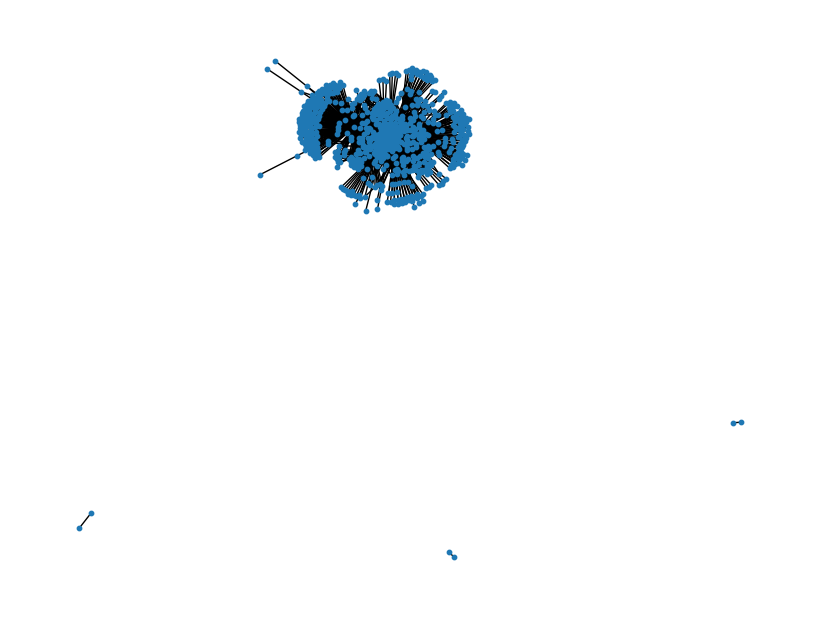

In [18]:
plt.figure(figsize=(8,6))
nx.draw(G, node_size=10)
plt.show()

The visualisation through the graph portrays how users are connected through shared discussions.
In the graph, the clusters created indicate such group of users which interact frequenctly.
Since there is a large and dense cluster in the mid, it depicts the presense of active communities where multiple users frequently interact within the same threads.
We can also see several small disconnnected components and isloated nodes which represent users who either interacted in smaller groups or particiapted in less active discussions.
Overall, the network appears to be highly clustered with a dominent connected component, which is typical of social interaction networks.

Since the graph is little too dense it is hard to read, so we can revise the plot by taking a smaller subgraph

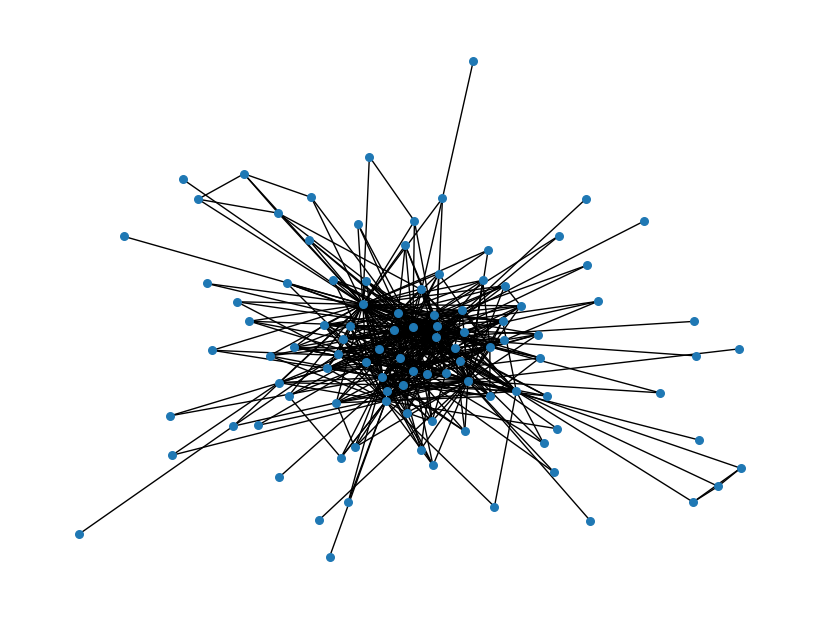

In [19]:
plt.figure(figsize=(8,6))

sub_nodes = list(G.nodes())[:100]
subgraph = G.subgraph(sub_nodes)

nx.draw(subgraph, node_size=30)
plt.show()

To improve the readability, a smaller subgraph is visualised. This allows clearer observations of the connections and local structures within the network.